# Model Justification: Distribution Checks
## 모형 선택 근거: 종속변수 분포 확인

This notebook plots the distribution of each dependent variable and shows the statistical properties that justify the model choice.

| DV | Model | Why |
|---|---|---|
| Revisit | M1 Logistic | Binary outcome |
| Keyword Count | M2 Ordered Logistic | Ordinal 0–5, unequal intervals |
| Rating | M3 Ordered Logistic | Ordinal 1–5, heavy ceiling |
| Reactions | M4 Negative Binomial | Count, overdispersed (var >> mean) |

In [1]:
import sys
try:
    sys.stdout.reconfigure(encoding='utf-8')
    sys.stderr.reconfigure(encoding='utf-8')
except AttributeError:
    pass  # Jupyter OutStream does not support reconfigure

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats
from pathlib import Path

# Korean font
for fp in ('C:/Windows/Fonts/malgunbd.ttf', 'C:/Windows/Fonts/malgun.ttf'):
    if Path(fp).exists():
        fm.fontManager.addfont(fp)
        plt.rcParams['font.family'] = fm.FontProperties(fname=fp).get_name()
        break
plt.rcParams['axes.unicode_minus'] = False

DATA = Path('../data/analysis/naver/naver_dataset.csv')
df = pd.read_csv(DATA, encoding='utf-8-sig')
print(f'Loaded {len(df):,} rows  ×  {df.shape[1]} columns')
print(f'Places: {df.place.nunique()}   Users: {df.user_id.nunique()}')

Loaded 14,401 rows  ×  57 columns
Places: 29   Users: 8276


---
## 1. Revisit — Binary → Logistic Regression (M1)

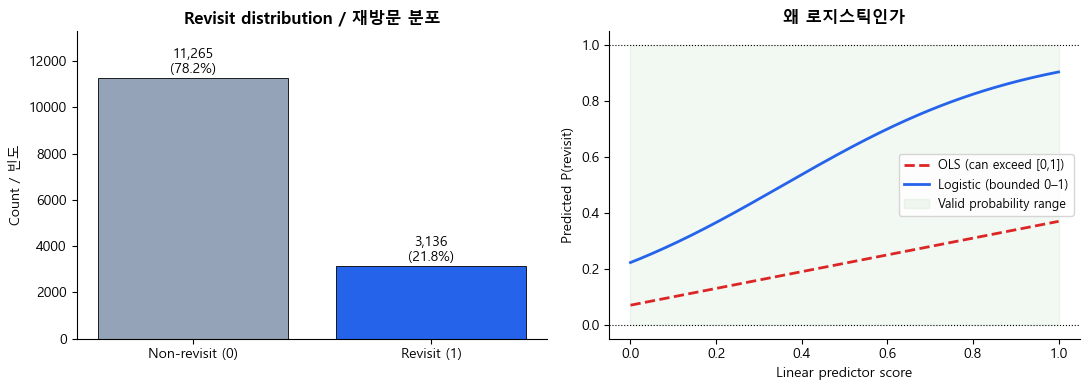


Revisit = 1: 3,136  (21.8%)
Revisit = 0: 11,265  (78.2%)
Class imbalance ratio: 3.6 : 1


In [7]:
revisit = df['revisit'].dropna()
counts  = revisit.value_counts().sort_index()
pct     = revisit.value_counts(normalize=True).sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Bar chart
bars = axes[0].bar(['Non-revisit (0)', 'Revisit (1)'], counts.values,
                   color=['#94a3b8', '#2563EB'], edgecolor='black', linewidth=0.6)
for bar, n, p in zip(bars, counts.values, pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
                 f'{n:,}\n({p:.1f}%)', ha='center', va='bottom', fontsize=10)
axes[0].set_title('Revisit distribution / 재방문 분포', fontweight='bold')
axes[0].set_ylabel('Count / 빈도')
axes[0].set_ylim(0, counts.max() * 1.18)
axes[0].spines[['top','right']].set_visible(False)

# Why logistic — show what OLS would do
x  = np.linspace(0, 1, 200)
# Simulated OLS line (passes through class means)
ols_line = 0.22 + 0.3 * (x - 0.5)
logit_p  = 1 / (1 + np.exp(-( -1.25 + 3.5 * x )))
axes[1].plot(x, ols_line,  '--', color='#DC2626', lw=2, label='OLS (can exceed [0,1])')
axes[1].plot(x, logit_p,   '-',  color='#2563EB', lw=2, label='Logistic (bounded 0–1)')
axes[1].axhline(0, color='black', lw=0.8, ls=':')
axes[1].axhline(1, color='black', lw=0.8, ls=':')
axes[1].fill_between(x, 0, 1, alpha=0.05, color='green', label='Valid probability range')
axes[1].set_title('왜 로지스틱인가', fontweight='bold')
axes[1].set_xlabel('Linear predictor score')
axes[1].set_ylabel('Predicted P(revisit)')
axes[1].legend(fontsize=9)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

print(f'\nRevisit = 1: {counts[1]:,}  ({pct[1]:.1f}%)')
print(f'Revisit = 0: {counts[0]:,}  ({pct[0]:.1f}%)')
print(f'Class imbalance ratio: {counts[0]/counts[1]:.1f} : 1')

---
## 2. Keyword Count — Ordinal 0–5 → Ordered Logistic (M2)

Key question: should we treat it as continuous (OLS) or ordinal? We check whether the gaps between categories are equal.

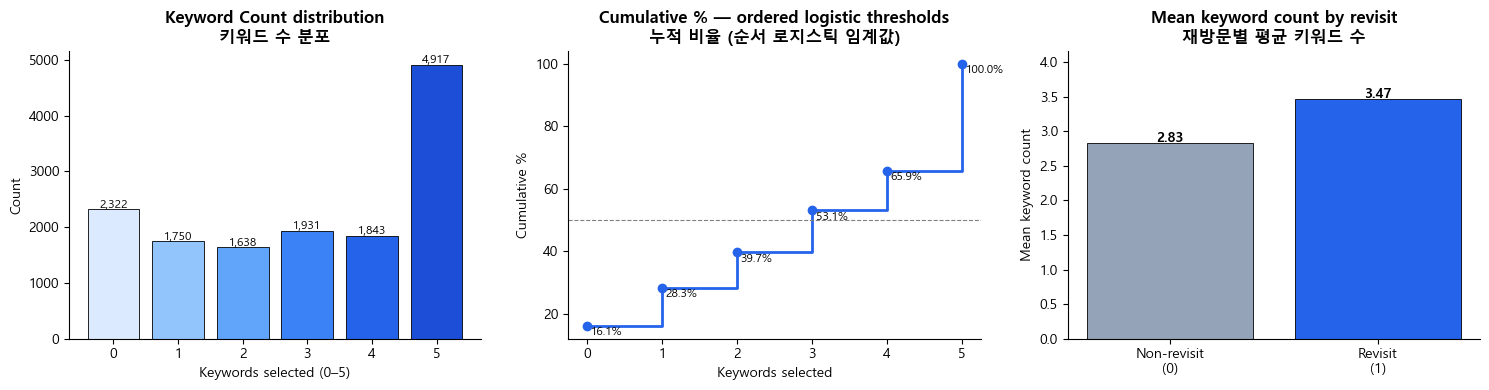

Mean: 2.970   Median: 3   Std: 1.883
Skewness: -0.339   Kurtosis: -1.374

Cumulative %:
n_tags
0     16.1
1     28.3
2     39.7
3     53.1
4     65.9
5    100.0

→ Gaps between categories are NOT equal: ordered logistic is appropriate.


In [3]:
kw = df['n_tags'].dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Distribution
counts_kw = kw.value_counts().sort_index()
colors_kw = ['#dbeafe','#93c5fd','#60a5fa','#3b82f6','#2563EB','#1d4ed8']
axes[0].bar(counts_kw.index, counts_kw.values, color=colors_kw,
            edgecolor='black', linewidth=0.6)
for x_val, y_val in zip(counts_kw.index, counts_kw.values):
    axes[0].text(x_val, y_val + 30, f'{y_val:,}', ha='center', fontsize=8.5)
axes[0].set_title('Keyword Count distribution\n키워드 수 분포', fontweight='bold')
axes[0].set_xlabel('Keywords selected (0–5)')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(6))
axes[0].spines[['top','right']].set_visible(False)

# Cumulative proportion — basis for ordered logistic thresholds
cum_prop = counts_kw.cumsum() / counts_kw.sum() * 100
axes[1].step(cum_prop.index, cum_prop.values, where='post',
             color='#2563EB', lw=2)
axes[1].scatter(cum_prop.index, cum_prop.values, color='#2563EB', zorder=5)
for x_val, y_val in zip(cum_prop.index, cum_prop.values):
    axes[1].text(x_val + 0.05, y_val - 3, f'{y_val:.1f}%', fontsize=8.5)
axes[1].axhline(50, ls='--', color='gray', lw=0.8)
axes[1].set_title('Cumulative % — ordered logistic thresholds\n누적 비율 (순서 로지스틱 임계값)', fontweight='bold')
axes[1].set_xlabel('Keywords selected')
axes[1].set_ylabel('Cumulative %')
axes[1].set_xticks(range(6))
axes[1].spines[['top','right']].set_visible(False)

# Mean keyword by revisit — shows ordinal relationship
means = df.groupby('revisit')['n_tags'].mean()
axes[2].bar(['Non-revisit\n(0)', 'Revisit\n(1)'], means.values,
            color=['#94a3b8','#2563EB'], edgecolor='black', linewidth=0.6)
for i, (lbl, m) in enumerate(means.items()):
    axes[2].text(i, m + 0.02, f'{m:.2f}', ha='center', fontweight='bold')
axes[2].set_title('Mean keyword count by revisit\n재방문별 평균 키워드 수', fontweight='bold')
axes[2].set_ylabel('Mean keyword count')
axes[2].set_ylim(0, means.max() * 1.2)
axes[2].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

print(f'Mean: {kw.mean():.3f}   Median: {kw.median():.0f}   Std: {kw.std():.3f}')
print(f'Skewness: {kw.skew():.3f}   Kurtosis: {kw.kurtosis():.3f}')
print('\nCumulative %:')
print((counts_kw.cumsum() / counts_kw.sum() * 100).round(1).to_string())
print('\n→ Gaps between categories are NOT equal: ordered logistic is appropriate.')

---
## 3. Rating — Ordinal 1–5 (ceiling effect) → Ordered Logistic M3

Note: only ~32% of reviews have a rating. Heavy ceiling at 5 stars.

Reviews with rating: 4,652 / 14,401  (32.3%)


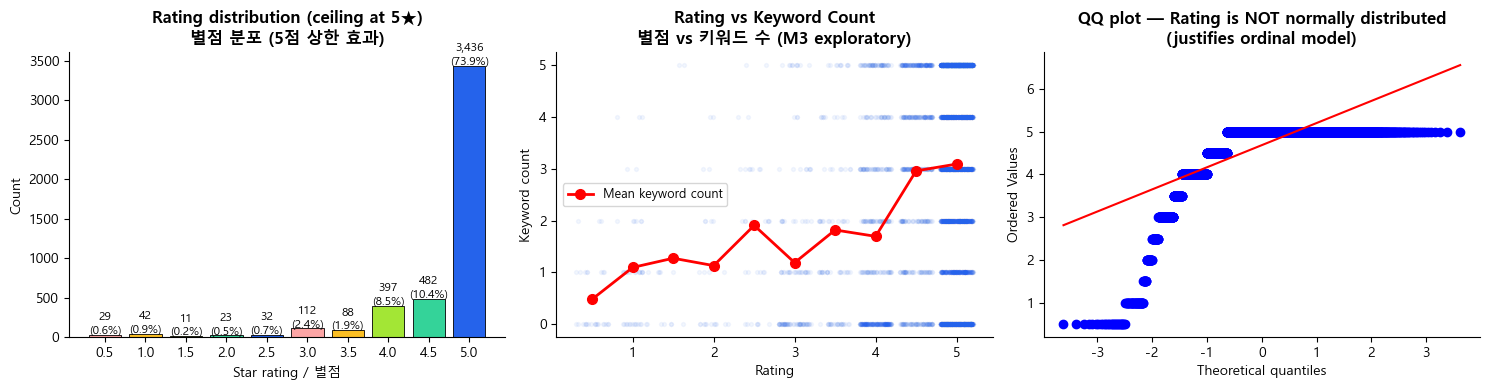

Mean: 4.682   Median: 5.0   Std: 0.732
Skewness: -3.311  (negative = left skewed / ceiling effect)
% with 5 stars: 73.9%

→ Strong ceiling at 5★. OLS would underestimate ceiling probability. Ordered logistic correct.


In [4]:
rating = df['rating'].dropna()
print(f'Reviews with rating: {len(rating):,} / {len(df):,}  ({len(rating)/len(df)*100:.1f}%)')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Distribution
r_counts = rating.value_counts().sort_index()
colors_r  = ['#fca5a5','#fbbf24','#a3e635','#34d399','#2563EB']
axes[0].bar(r_counts.index.astype(str), r_counts.values,
            color=colors_r, edgecolor='black', linewidth=0.6)
for x_val, y_val in zip(r_counts.index.astype(str), r_counts.values):
    axes[0].text(x_val, y_val + 10, f'{y_val:,}\n({y_val/len(rating)*100:.1f}%)',
                 ha='center', fontsize=8.5)
axes[0].set_title('Rating distribution (ceiling at 5★)\n별점 분포 (5점 상한 효과)', fontweight='bold')
axes[0].set_xlabel('Star rating / 별점')
axes[0].set_ylabel('Count')
axes[0].spines[['top','right']].set_visible(False)

# Rating vs keyword count scatter (with jitter)
sub = df[['rating','n_tags']].dropna()
jitter = np.random.uniform(-0.2, 0.2, len(sub))
axes[1].scatter(sub['rating'] + jitter, sub['n_tags'],
                alpha=0.05, s=8, color='#2563EB')
means_r = sub.groupby('rating')['n_tags'].mean()
axes[1].plot(means_r.index, means_r.values, 'ro-', lw=2, ms=7, label='Mean keyword count')
axes[1].set_title('Rating vs Keyword Count\n별점 vs 키워드 수 (M3 exploratory)', fontweight='bold')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Keyword count')
axes[1].legend(fontsize=9)
axes[1].spines[['top','right']].set_visible(False)

# Normality check — QQ plot (shows it is NOT normal → OLS inappropriate)
stats.probplot(rating, dist='norm', plot=axes[2])
axes[2].set_title('QQ plot — Rating is NOT normally distributed\n(justifies ordinal model)', fontweight='bold')
axes[2].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

print(f'Mean: {rating.mean():.3f}   Median: {rating.median():.1f}   Std: {rating.std():.3f}')
print(f'Skewness: {rating.skew():.3f}  (negative = left skewed / ceiling effect)')
print(f'% with 5 stars: {(rating == 5).mean()*100:.1f}%')
print('\n→ Strong ceiling at 5★. OLS would underestimate ceiling probability. Ordered logistic correct.')

---
## 4. Reactions — Count, overdispersed → Negative Binomial (M4)

Key test: is variance ≈ mean (Poisson) or variance >> mean (Negative Binomial)?

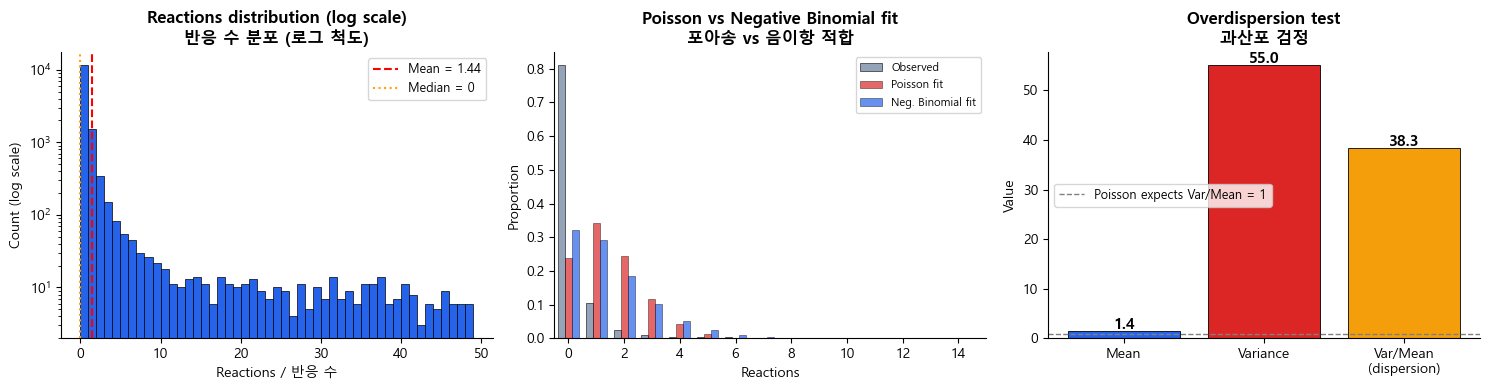

Mean:               1.437
Variance:           54.984
Dispersion (V/M):   38.3×  ← Poisson assumes 1×
% zero reactions:   80.9%
Max reactions:      122

α̂ = 2.44  →  variance ≈ mean × (1 + mean/α) ≈ mean × 1.6

→ Variance is 37× the mean. Poisson severely underestimates SE → false significance.
→ Negative Binomial with dispersion parameter α is the correct choice.


In [5]:
rx = df['reactions'].dropna()

mean_rx = rx.mean()
var_rx  = rx.var()
disp    = var_rx / mean_rx   # dispersion ratio; Poisson assumes = 1

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Raw distribution (log y-axis to show the tail)
axes[0].hist(rx, bins=range(0, min(rx.max()+2, 50)), color='#2563EB',
             edgecolor='black', linewidth=0.5, log=True)
axes[0].axvline(mean_rx, color='red',  ls='--', lw=1.5, label=f'Mean = {mean_rx:.2f}')
axes[0].axvline(rx.median(), color='orange', ls=':', lw=1.5,
                label=f'Median = {rx.median():.0f}')
axes[0].set_title('Reactions distribution (log scale)\n반응 수 분포 (로그 척도)', fontweight='bold')
axes[0].set_xlabel('Reactions / 반응 수')
axes[0].set_ylabel('Count (log scale)')
axes[0].legend(fontsize=9)
axes[0].spines[['top','right']].set_visible(False)

# Overdispersion: Poisson vs NB fitted PMF
from scipy.stats import poisson, nbinom
k_vals = np.arange(0, 20)
# Poisson: lambda = mean
poisson_pmf = poisson.pmf(k_vals, mu=mean_rx)
# NB: fit via method of moments (alpha from descriptive stats)
alpha_hat = 2.44
p_nb  = alpha_hat / (alpha_hat + mean_rx)
nb_pmf = nbinom.pmf(k_vals, n=alpha_hat, p=p_nb)
obs_prop = rx.value_counts(normalize=True).reindex(k_vals, fill_value=0)

axes[1].bar(k_vals - 0.25, obs_prop.values, width=0.25, label='Observed',
            color='#94a3b8', edgecolor='black', linewidth=0.4)
axes[1].bar(k_vals,        poisson_pmf,      width=0.25, label='Poisson fit',
            color='#DC2626', alpha=0.7, edgecolor='black', linewidth=0.4)
axes[1].bar(k_vals + 0.25, nb_pmf,           width=0.25, label='Neg. Binomial fit',
            color='#2563EB', alpha=0.7, edgecolor='black', linewidth=0.4)
axes[1].set_xlim(-0.5, 15)
axes[1].set_title('Poisson vs Negative Binomial fit\n포아송 vs 음이항 적합', fontweight='bold')
axes[1].set_xlabel('Reactions')
axes[1].set_ylabel('Proportion')
axes[1].legend(fontsize=8)
axes[1].spines[['top','right']].set_visible(False)

# Overdispersion summary panel
labels = ['Mean', 'Variance', 'Var/Mean\n(dispersion)']
values = [mean_rx, var_rx, disp]
bar_colors = ['#2563EB', '#DC2626', '#f59e0b']
bars = axes[2].bar(labels, values, color=bar_colors, edgecolor='black', linewidth=0.6)
for bar, v in zip(bars, values):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{v:.1f}', ha='center', fontweight='bold', fontsize=11)
axes[2].axhline(1, ls='--', color='gray', lw=1, label='Poisson expects Var/Mean = 1')
axes[2].set_title('Overdispersion test\n과산포 검정', fontweight='bold')
axes[2].set_ylabel('Value')
axes[2].legend(fontsize=9)
axes[2].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

print(f'Mean:               {mean_rx:.3f}')
print(f'Variance:           {var_rx:.3f}')
print(f'Dispersion (V/M):   {disp:.1f}×  ← Poisson assumes 1×')
print(f'% zero reactions:   {(rx == 0).mean()*100:.1f}%')
print(f'Max reactions:      {rx.max()}')
print(f'\nα̂ = 2.44  →  variance ≈ mean × (1 + mean/α) ≈ mean × {1 + mean_rx/2.44:.1f}')
print('\n→ Variance is 37× the mean. Poisson severely underestimates SE → false significance.')
print('→ Negative Binomial with dispersion parameter α is the correct choice.')

---
## 5. Summary: Why each model

| DV | Mean | Median | Std | Skew | Decision |
|---|---|---|---|---|---|
| Revisit | 0.22 | 0 | 0.41 | 1.35 | Binary → Logistic |
| Keyword Count | 2.97 | 3 | 1.88 | −0.06 | Ordinal, unequal gaps → Ordered Logistic |
| Rating | 4.68 | 5 | 0.73 | −2.50 | Ordinal, ceiling effect → Ordered Logistic |
| Reactions | 1.44 | 0 | 7.42 | 10.7 | Count, overdispersion 37× → Neg. Binomial |

In [6]:
dvs = {
    'Revisit\n재방문': df['revisit'].dropna(),
    'Keyword Count\n키워드 수': df['n_tags'].dropna(),
    'Rating\n별점': df['rating'].dropna(),
    'Reactions\n반응 수': df['reactions'].dropna(),
}

summary = []
for name, s in dvs.items():
    summary.append({
        'Variable': name.replace('\n','  '),
        'N': f'{len(s):,}',
        'Mean':   f'{s.mean():.2f}',
        'Median': f'{s.median():.0f}',
        'Std':    f'{s.std():.2f}',
        'Min':    f'{s.min():.0f}',
        'Max':    f'{s.max():.0f}',
        'Skewness': f'{s.skew():.2f}',
        'Var/Mean': f'{s.var()/s.mean():.1f}×',
    })

pd.DataFrame(summary).set_index('Variable')

,N,Mean,Median,Std,Min,Max,Skewness,Var/Mean
Variable,,,,,,,,
Revisit 재방문,"14,401",0.22,0,0.41,0,1,1.37,0.8×
Keyword Count 키워드 수,"14,401",2.97,3,1.88,0,5,-0.34,1.2×
Rating 별점,"4,652",4.68,5,0.73,0,5,-3.31,0.1×
Reactions 반응 수,"14,401",1.44,0,7.42,0,122,7.97,38.3×
